# Hate speech classification

TF-IDF features and Gaussian Naive Bayes on the public Davidson dataset. The implementation lives in `classifier.py`.

Install `requirements.txt`, select the project `.venv`, and run all cells from the repository directory. The source data contains offensive language.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from classifier import download, load_dataset, train

dataset = download()
data, cleaning = load_dataset(dataset)
pd.Series(cleaning, name="Rows and groups")

input_rows                  24783
conflicting_groups              1
conflicting_rows_removed        2
duplicate_rows_removed         11
output_rows                 24770
Name: Rows and groups, dtype: int64

## Data

Original hate-speech class `0` maps to `1`; offensive language and neither map to `0`. Non-hate does not mean harmless. Conflicting and repeated texts are removed before splitting; IDs and annotation votes are excluded from model input.

In [2]:
data["label"].value_counts().rename(index={0: "Non-hate", 1: "Hate"}).to_frame(
    "Posts"
)

,Posts
label,
Non-hate,23341
Hate,1429


## Train and evaluate

Reserve 20% for evaluation, preserving class proportions (seed 42). Five-fold cross-validation selects smoothing by macro F1, weighting both classes equally. TF-IDF is fitted inside each fold, capped at 2,000 features.

This takes a few minutes. Evaluation is saved before refitting on all cleaned rows for prediction.

In [3]:
report = train(dataset)
pd.DataFrame(
    {
        name: {
            "Accuracy": report[key]["accuracy"],
            "Macro F1": report[key]["macro_f1"],
            "Hate precision": report[key]["classification_report"]["hate"][
                "precision"
            ],
            "Hate recall": report[key]["classification_report"]["hate"][
                "recall"
            ],
        }
        for name, key in [
            ("Gaussian NB", "holdout"),
            ("Majority baseline", "majority_baseline"),
        ]
    }
).T

,Accuracy,Macro F1,Hate precision,Hate recall
Gaussian NB,0.923092,0.693778,0.375328,0.5
Majority baseline,0.942269,0.485138,0.000000,0.0


## Evaluation figure

The left panel shows counts and percentages within each actual class. The right compares the model with always predicting non-hate. Both use the untouched holdout evaluated above, before the full-data refit. This cell displays the figure and saves `results.png` for the README.

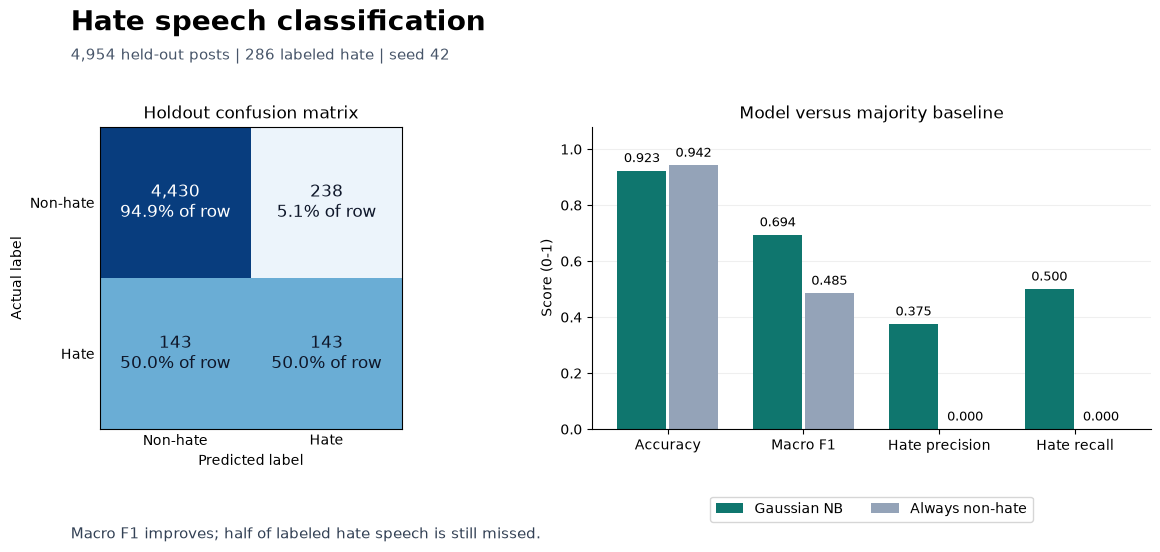

In [4]:
matrix = np.asarray(report["holdout"]["confusion_matrix"])
row_rates = matrix / matrix.sum(axis=1, keepdims=True)
metrics = ["Accuracy", "Macro F1", "Hate precision", "Hate recall"]
scores = [
    [
        report[key]["accuracy"],
        report[key]["macro_f1"],
        report[key]["classification_report"]["hate"]["precision"],
        report[key]["classification_report"]["hate"]["recall"],
    ]
    for key in ["holdout", "majority_baseline"]
]

fig, (cm_ax, score_ax) = plt.subplots(
    1, 2, figsize=(12, 5.6), gridspec_kw={"width_ratios": [1, 1.55]}
)
fig.subplots_adjust(left=0.08, right=0.98, top=0.77, bottom=0.23, wspace=0.35)
fig.suptitle(
    "Hate speech classification",
    x=0.08,
    y=0.98,
    ha="left",
    fontsize=20,
    fontweight="bold",
)
fig.text(
    0.08,
    0.89,
    f"{matrix.sum():,} held-out posts | "
    f"{matrix[1].sum():,} labeled hate | seed {report['split']['seed']}",
    fontsize=11,
    color="#475569",
)

cm_ax.imshow(row_rates, cmap="Blues", vmin=0, vmax=1)
cm_ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=["Non-hate", "Hate"],
    yticklabels=["Non-hate", "Hate"],
    xlabel="Predicted label",
    ylabel="Actual label",
    title="Holdout confusion matrix",
)
for (row, col), count in np.ndenumerate(matrix):
    cm_ax.text(
        col,
        row,
        f"{count:,}\n{row_rates[row, col]:.1%} of row",
        ha="center",
        va="center",
        fontsize=12,
        color="white" if row_rates[row, col] > 0.6 else "#0F172A",
    )
cm_ax.tick_params(length=0)

positions = np.arange(len(metrics))
for offset, values, name, color in [
    (-0.19, scores[0], "Gaussian NB", "#0F766E"),
    (0.19, scores[1], "Always non-hate", "#94A3B8"),
]:
    bars = score_ax.bar(
        positions + offset, values, 0.36, label=name, color=color
    )
    score_ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)
score_ax.set(
    xticks=positions,
    xticklabels=metrics,
    ylim=(0, 1.08),
    ylabel="Score (0-1)",
    title="Model versus majority baseline",
)
score_ax.set_axisbelow(True)
score_ax.grid(axis="y", alpha=0.2)
score_ax.spines[["top", "right"]].set_visible(False)
score_ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
fig.text(
    0.08,
    0.035,
    "Macro F1 improves; half of labeled hate speech is still missed.",
    fontsize=11,
    color="#334155",
)
fig.savefig("results.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.show()

## Use and limitations

```text
python classifier.py predict --input posts.csv --output artifacts/predictions.csv
```

Input: `id,tweet`. Output: `id,label`. Metrics and versions: `artifacts/metrics.json`.

Gaussian assumptions are a poor fit for sparse text features. This historical dataset has subjective labels and documented bias; results do not establish suitability for moderation.

[Dataset](https://github.com/t-davidson/hate-speech-and-offensive-language) | [Paper](https://arxiv.org/abs/1703.04009) | [Bias study](https://arxiv.org/abs/1905.12516). See the README for setup and attribution.